# Project 3 Draft — Dialogue Summarization with a BERT Encoder-Decoder

**(CRISP-DM: Business Understanding)** **Scenario.** Acme Communications users lose important details in long group chats. This notebook builds a proof-of-concept that condenses messenger-style conversations into short summaries, using the **SAMSum** dataset and a **pre-trained BERT encoder + GPT-2 decoder** (warm-started `EncoderDecoderModel` from Hugging Face).

**Pipeline**
1. Data exploration and preparation
2. Model architecture design and implementation
3. Training and optimization (early stopping + checkpointing)
4. Evaluation (ROUGE) and error analysis
5. Inference demo, findings and next steps

> **Status: MVP draft (~90%).** The full pipeline runs end to end. The trained model writes fluent, correctly formatted summaries but does not yet use the conversation's content; Sections 6 and 8 explain why and set out the plan for the final version.
>
> **Run environment for this draft:** Windows 11, Python 3.11, PyTorch with CUDA 12.6, transformers 4.57, on an **NVIDIA GeForce GTX 1650 SUPER (4 GB)**. Training on 3,000 dialogues took **223 minutes**; generating test summaries took about 12 minutes (greedy) and 22 minutes (beam search). On a Colab T4 the same run takes roughly 20–30 minutes.

### CRISP-DM roadmap
This notebook follows the CRISP-DM process. Each section heading names the phase it covers.

| CRISP-DM phase | Where it happens in this notebook |
|---|---|
| Business Understanding | Acme scenario (title cell above) |
| Data Understanding | Section 1 |
| Data Preparation | Sections 1–2 |
| Modeling | Sections 3–4 |
| Evaluation | Sections 5–6 |
| Deployment | Sections 7–8 |

## 0. Setup

In [1]:
import os, re, json, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader

import nltk
import evaluate
import transformers
from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    EncoderDecoderModel,
    Seq2SeqTrainer,
    Seq2SeqTrainingArguments,
    DataCollatorForSeq2Seq,
    EarlyStoppingCallback,
    set_seed,
)

nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)

SEED = 42
set_seed(SEED)
pd.set_option("display.max_colwidth", 200)
plt.rcParams["figure.dpi"] = 110

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("transformers:", transformers.__version__, "| torch:", torch.__version__)
print("device:", device)
if device.type == "cuda":
    props = torch.cuda.get_device_properties(0)
    print(f"GPU: {props.name} ({props.total_memory / 1e9:.1f} GB)")

transformers: 4.57.6 | torch: 2.14.1+cu126
device: cuda
GPU: NVIDIA GeForce GTX 1650 SUPER (4.3 GB)


### Configuration
All design choices live here so experiments are easy to reproduce.

* **Encoder:** `bert-base-uncased`, a pre-trained bidirectional encoder that reads the whole dialogue.
* **Decoder:** `gpt2`, a free, pre-trained autoregressive text generator. Its cross-attention layers (which let it "look at" the BERT encoding) are newly initialized and learned during fine-tuning. Set `DECODER_NAME = "bert-base-uncased"` to run the **BERT2BERT** variant for comparison.
* **Subset:** SAMSum has about 14.7k training dialogues. `USE_SUBSET=True` trains on 3,000 for fast iteration; set it to `False` for the final run, which gives noticeably better ROUGE.

In [2]:
# ---- Model ----
ENCODER_NAME = "bert-base-uncased"
DECODER_NAME = "gpt2"            # alternative: "bert-base-uncased" (BERT2BERT)

# ---- Sequence lengths (chosen from the token-length analysis in Section 2) ----
MAX_INPUT_LEN = 512              # BERT's hard limit
MAX_TARGET_LEN = 128

# ---- Data size ----
USE_SUBSET = True                # False -> full ~14.7k training dialogues
TRAIN_SUBSET_SIZE = 3000
VAL_EVAL_SIZE = 200              # validation examples scored with ROUGE during training
TEST_SUBSET_SIZE = None          # None -> full test set (819)

# ---- Optimization ----
BATCH_SIZE = 8
GRAD_ACCUM = 2                   # effective batch = 16
LEARNING_RATE = 5e-5
NUM_EPOCHS = 5
WARMUP_RATIO = 0.1
WEIGHT_DECAY = 0.01
EVAL_STEPS = 200 if USE_SUBSET else 500
PATIENCE = 3                     # early stopping: evals without ROUGE-L improvement

# ---- Paths (on Colab, point these at Google Drive to survive disconnects) ----
OUTPUT_DIR = "checkpoints/bert2gpt2-samsum"
FINAL_MODEL_DIR = "models/bert2gpt2-samsum-final"
RESUME_FROM_CHECKPOINT = False   # True -> resume from latest checkpoint in OUTPUT_DIR

In [3]:
# Optional: persist checkpoints to Google Drive on Colab
# from google.colab import drive
# drive.mount("/content/drive")
# OUTPUT_DIR = "/content/drive/MyDrive/project3/checkpoints"
# FINAL_MODEL_DIR = "/content/drive/MyDrive/project3/final_model"

## 1. Dataset Exploration and Preparation (CRISP-DM: Data Understanding & Data Preparation)

In [4]:
raw = load_dataset("knkarthick/samsum")
print(raw)

ex = raw["train"][0]
print("\n--- DIALOGUE ---\n" + ex["dialogue"])
print("\n--- SUMMARY ---\n" + ex["summary"])

DatasetDict({
    train: Dataset({
        features: ['id', 'dialogue', 'summary'],
        num_rows: 14731
    })
    validation: Dataset({
        features: ['id', 'dialogue', 'summary'],
        num_rows: 818
    })
    test: Dataset({
        features: ['id', 'dialogue', 'summary'],
        num_rows: 819
    })
})

--- DIALOGUE ---
Amanda: I baked  cookies. Do you want some?
Jerry: Sure!
Amanda: I'll bring you tomorrow :-)

--- SUMMARY ---
Amanda baked cookies and will bring Jerry some tomorrow.


### Cleaning
SAMSum contains Windows line endings, placeholder tokens such as `<file_photo>`, and a few empty records. We normalize whitespace, turn file placeholders into short readable tags (`[photo]`), and drop empty examples.

In [5]:
def clean_text(t):
    if t is None:
        return ""
    t = t.replace("\r\n", "\n").replace("\r", "\n")
    t = re.sub(r"<file_(\w+)>", r"[\1]", t)      # <file_photo> -> [photo]
    t = re.sub(r"[ \t]+", " ", t)
    t = re.sub(r"\n+", "\n", t)
    return t.strip()

def clean_example(ex):
    return {"dialogue": clean_text(ex["dialogue"]), "summary": clean_text(ex["summary"])}

before = {k: len(v) for k, v in raw.items()}
ds = raw.map(clean_example)
ds = ds.filter(lambda ex: len(ex["dialogue"]) > 0 and len(ex["summary"]) > 0)
after = {k: len(v) for k, v in ds.items()}
print("before:", before)
print("after: ", after)

before: {'train': 14731, 'validation': 818, 'test': 819}
after:  {'train': 14731, 'validation': 818, 'test': 819}


### Dialogue and summary characteristics

In [6]:
SPEAKER_RE = re.compile(r"^([^:\n]{1,40}):", re.MULTILINE)

def speakers_of(dialogue):
    return {s.strip() for s in SPEAKER_RE.findall(dialogue)}

def dialogue_stats(df):
    df = df.copy()
    df["dlg_words"] = df["dialogue"].str.split().str.len()
    df["sum_words"] = df["summary"].str.split().str.len()
    df["turns"] = df["dialogue"].str.count("\n") + 1
    df["speakers"] = df["dialogue"].apply(lambda d: len(speakers_of(d)))
    df["compression"] = df["sum_words"] / df["dlg_words"]
    return df

train_df = dialogue_stats(ds["train"].to_pandas())
train_df[["dlg_words", "sum_words", "turns", "speakers", "compression"]] \
    .describe(percentiles=[.5, .9, .95, .99]).round(2)

,dlg_words,sum_words,turns,speakers,compression
count,14731.00,14731.00,14731.00,14731.00,14731.00
mean,93.79,20.32,11.17,2.39,0.30
std,74.03,11.15,6.45,0.83,0.18
min,7.00,1.00,3.00,2.00,0.02
50%,73.00,18.00,10.00,2.00,0.26
90%,191.00,37.00,20.00,3.00,0.53
95%,237.00,43.00,24.00,4.00,0.64
99%,351.00,53.00,29.00,5.00,0.87
max,803.00,64.00,46.00,14.00,1.89


In [7]:
print("Speakers per dialogue (% of training set):")
print((train_df["speakers"].clip(upper=6).value_counts(normalize=True).sort_index() * 100).round(1)
      .rename(index={6: "6+"}))

Speakers per dialogue (% of training set):
speakers
2     73.0
3     19.1
4      5.6
5      1.3
6+     1.0
Name: proportion, dtype: float64


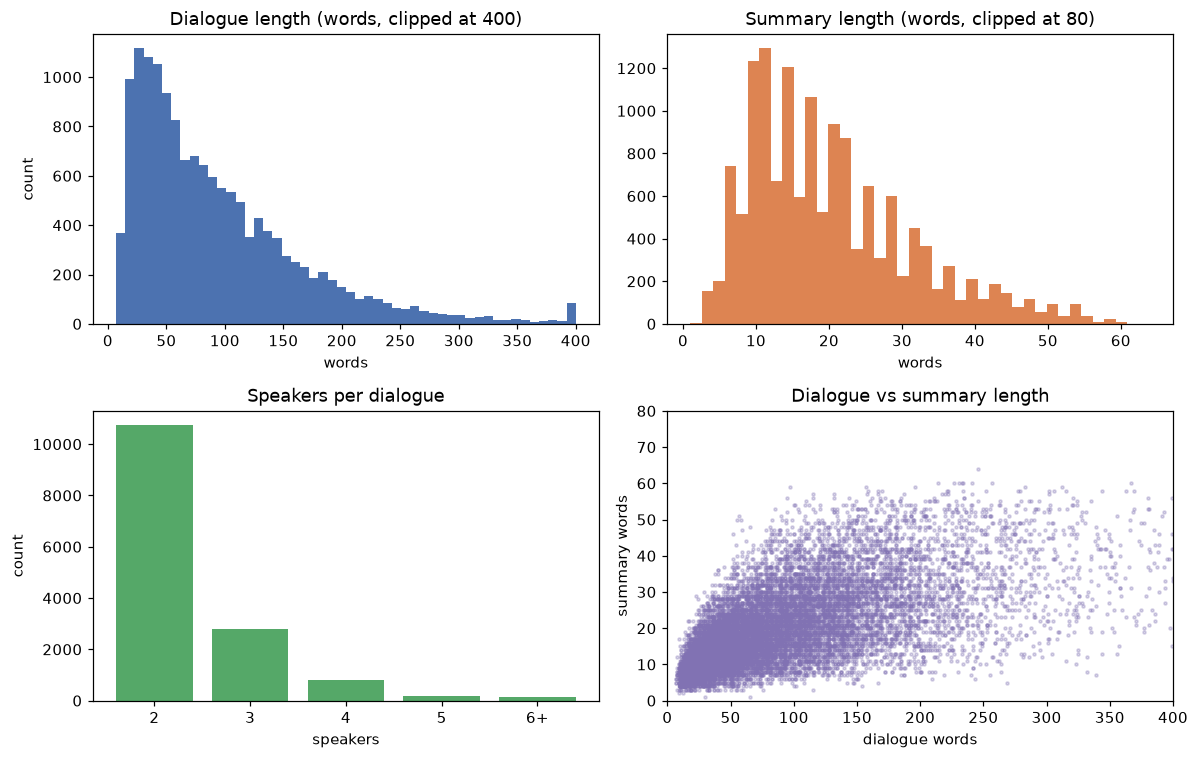

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))

axes[0, 0].hist(train_df["dlg_words"].clip(upper=400), bins=50, color="#4C72B0")
axes[0, 0].set(title="Dialogue length (words, clipped at 400)", xlabel="words", ylabel="count")

axes[0, 1].hist(train_df["sum_words"].clip(upper=80), bins=40, color="#DD8452")
axes[0, 1].set(title="Summary length (words, clipped at 80)", xlabel="words")

spk = train_df["speakers"].clip(upper=6).value_counts().sort_index()
axes[1, 0].bar([str(i) if i < 6 else "6+" for i in spk.index], spk.values, color="#55A868")
axes[1, 0].set(title="Speakers per dialogue", xlabel="speakers", ylabel="count")

axes[1, 1].scatter(train_df["dlg_words"], train_df["sum_words"], s=4, alpha=0.3, color="#8172B3")
axes[1, 1].set(title="Dialogue vs summary length", xlabel="dialogue words", ylabel="summary words",
               xlim=(0, 400), ylim=(0, 80))

plt.tight_layout()
plt.show()

**Observations (from the statistics above)**
* **Dialogues are short chat exchanges.** The average is **94 words** (median 73) over about **11 turns**, with a long tail: 5% exceed 237 words and the longest is 803.
* **Summaries are about 20 words** (median 18, max 64): typically one or two third-person sentences. The median summary is about **26% of the dialogue's length**, roughly a 4× compression.
* **Most chats are one-to-one.** **73%** have two speakers, 19% have three, and 8% have four or more. Group chats are a minority of the data but are exactly the Acme use case.
* **Length limits are safe.** In BERT tokens the median dialogue is 108 tokens and **99%** fit within the 512-token limit; every summary fits within 128 GPT-2 tokens (median 23). Truncation therefore affects only about 1% of chats.
* **Summaries are abstractive.** They rephrase first-person chat ("I'll bring you tomorrow") into third-person reports ("Amanda ... will bring Jerry some tomorrow"). Copying sentences won't work, which motivates a generative model.

## 2. Tokenization and Data Loaders (CRISP-DM: Data Preparation)

The encoder and decoder have **different vocabularies**, so each side uses its own tokenizer:
* Dialogues → BERT WordPiece tokenizer (`[CLS] … [SEP]`).
* Summaries → GPT-2 byte-level BPE tokenizer. GPT-2 has no padding token, so we reuse `<|endoftext|>`, which also serves as the start and end-of-summary token.

In [9]:
enc_tok = AutoTokenizer.from_pretrained(ENCODER_NAME)
dec_tok = AutoTokenizer.from_pretrained(DECODER_NAME)
IS_GPT2_DECODER = "gpt2" in DECODER_NAME.lower()

if IS_GPT2_DECODER:
    dec_tok.pad_token = dec_tok.eos_token
    DEC_START_ID = dec_tok.bos_token_id      # <|endoftext|>
    EOS_ID = dec_tok.eos_token_id            # <|endoftext|>
    PAD_ID = dec_tok.pad_token_id            # <|endoftext|>
else:                                        # BERT2BERT
    DEC_START_ID = dec_tok.cls_token_id
    EOS_ID = dec_tok.sep_token_id
    PAD_ID = dec_tok.pad_token_id

print(f"decoder start={DEC_START_ID}, eos={EOS_ID}, pad={PAD_ID}, decoder vocab={len(dec_tok)}")

decoder start=50256, eos=50256, pad=50256, decoder vocab=50257


In [10]:
# Check how much of the data fits within our length limits
sample = ds["train"].shuffle(seed=SEED).select(range(2000))
in_lens = np.array([len(x) for x in enc_tok(list(sample["dialogue"]))["input_ids"]])
out_lens = np.array([len(x) + 1 for x in dec_tok(list(sample["summary"]), add_special_tokens=False)["input_ids"]])

for name, lens, limit in [("dialogue (BERT tokens)", in_lens, MAX_INPUT_LEN),
                          ("summary (GPT-2 tokens)", out_lens, MAX_TARGET_LEN)]:
    print(f"{name}: median={np.median(lens):.0f}, p95={np.percentile(lens, 95):.0f}, "
          f"max={lens.max()}, fits in {limit}: {(lens <= limit).mean() * 100:.1f}%")

Token indices sequence length is longer than the specified maximum sequence length for this model (616 > 512). Running this sequence through the model will result in indexing errors


dialogue (BERT tokens): median=108, p95=337, max=797, fits in 512: 99.0%
summary (GPT-2 tokens): median=23, p95=53, max=77, fits in 128: 100.0%


In [11]:
def preprocess(batch):
    model_inputs = enc_tok(
        batch["dialogue"],
        max_length=MAX_INPUT_LEN,
        truncation=True,
        return_token_type_ids=False,
    )
    targets = dec_tok(
        batch["summary"],
        add_special_tokens=False,
        max_length=MAX_TARGET_LEN - 1,
        truncation=True,
    )["input_ids"]
    # Append an explicit end-of-summary token so the model learns when to stop
    model_inputs["labels"] = [ids + [EOS_ID] for ids in targets]
    return model_inputs

train_raw = ds["train"].shuffle(seed=SEED)
if USE_SUBSET:
    train_raw = train_raw.select(range(min(TRAIN_SUBSET_SIZE, len(train_raw))))
val_raw = ds["validation"]
test_raw = ds["test"] if TEST_SUBSET_SIZE is None else ds["test"].select(range(TEST_SUBSET_SIZE))

cols = ds["train"].column_names
train_tok = train_raw.map(preprocess, batched=True, remove_columns=cols)
val_tok = val_raw.map(preprocess, batched=True, remove_columns=cols)
val_eval_tok = val_tok.shuffle(seed=SEED).select(range(min(VAL_EVAL_SIZE, len(val_tok))))

print(f"train: {len(train_tok)} | val (ROUGE during training): {len(val_eval_tok)} | test: {len(test_raw)}")

train: 3000 | val (ROUGE during training): 200 | test: 819


**Data loaders.** We use *dynamic padding*: each batch is padded only to its longest example instead of always to 512, which cuts compute substantially because most dialogues are short. Label padding uses `-100`, so padded positions are ignored by the loss.

In [12]:
collator = DataCollatorForSeq2Seq(
    tokenizer=enc_tok,
    label_pad_token_id=-100,
    pad_to_multiple_of=8 if device.type == "cuda" else None,
)

# Explicit DataLoader (the Trainer builds equivalent loaders internally)
train_loader = DataLoader(train_tok, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collator)
batch = next(iter(train_loader))
for k, v in batch.items():
    print(f"{k:15s} {tuple(v.shape)}")

print("\nDecoded input :", enc_tok.decode(batch["input_ids"][0], skip_special_tokens=True)[:250], "...")
lbl = batch["labels"][0]
print("Decoded target:", dec_tok.decode(lbl[lbl != -100]))

input_ids       (8, 184)
attention_mask  (8, 184)
labels          (8, 40)

Decoded input : peris : i cant eat this junk food anymore omari : why? peris : i have been planning to for dieting omari : great idea peris : what about you? omari : its been 2 months since i have been going to shapes peris : you didnt tell me : / ...
Decoded target: Peris want to start dieting. Omari has already been dieting for 2 months.<|endoftext|>


## 3. Model Architecture (CRISP-DM: Modeling)

```
 dialogue ──► BERT tokenizer ──► BERT encoder (12 layers, pre-trained)
                                        │  contextual embeddings (768-d per token)
                                        ▼
 <|endoftext|> ─► GPT-2 decoder (12 layers, pre-trained self-attention
                  + NEW cross-attention to encoder outputs) ──► LM head ──► summary tokens
```

* **Encoder (BERT):** bidirectional; produces a contextual representation of every dialogue token.
* **Decoder (GPT-2):** autoregressive; at each step it attends to previously generated tokens (masked self-attention) and to the encoder output (cross-attention).
* **Warm-starting:** both stacks keep their pre-trained weights. Only the cross-attention layers start random, which is why the loading step warns about newly initialized weights. That warning is expected.
* **Loss:** token-level cross-entropy with teacher forcing (`labels` are shifted right internally to form decoder inputs).
* **Generation:** greedy decoding or beam search, compared in Section 5.

In [13]:
model = EncoderDecoderModel.from_encoder_decoder_pretrained(ENCODER_NAME, DECODER_NAME)

# Special tokens the seq2seq wrapper needs (missing these is the #1 cause of garbage output)
model.config.decoder_start_token_id = DEC_START_ID
model.config.eos_token_id = EOS_ID
model.config.pad_token_id = PAD_ID
model.config.vocab_size = model.config.decoder.vocab_size

gen_cfg = model.generation_config
gen_cfg.decoder_start_token_id = DEC_START_ID
gen_cfg.eos_token_id = EOS_ID
gen_cfg.pad_token_id = PAD_ID

model.to(device)

def n_params(params):
    return sum(p.numel() for p in params)

total = n_params(model.parameters())
enc_p = n_params(model.encoder.parameters())
dec_p = n_params(model.decoder.parameters())
xattn = sum(p.numel() for n, p in model.decoder.named_parameters() if "cross" in n)
print(f"Total params:          {total / 1e6:7.1f}M")
print(f"  Encoder (BERT):      {enc_p / 1e6:7.1f}M")
print(f"  Decoder (GPT-2):     {dec_p / 1e6:7.1f}M")
print(f"    new cross-attn:    {xattn / 1e6:7.1f}M  (randomly initialized)")

Some weights of GPT2LMHeadModel were not initialized from the model checkpoint at gpt2 and are newly initialized: ['transformer.h.0.crossattention.c_attn.bias', 'transformer.h.0.crossattention.c_attn.weight', 'transformer.h.0.crossattention.c_proj.bias', 'transformer.h.0.crossattention.c_proj.weight', 'transformer.h.0.crossattention.q_attn.bias', 'transformer.h.0.crossattention.q_attn.weight', 'transformer.h.0.ln_cross_attn.bias', 'transformer.h.0.ln_cross_attn.weight', 'transformer.h.1.crossattention.c_attn.bias', 'transformer.h.1.crossattention.c_attn.weight', 'transformer.h.1.crossattention.c_proj.bias', 'transformer.h.1.crossattention.c_proj.weight', 'transformer.h.1.crossattention.q_attn.bias', 'transformer.h.1.crossattention.q_attn.weight', 'transformer.h.1.ln_cross_attn.bias', 'transformer.h.1.ln_cross_attn.weight', 'transformer.h.10.crossattention.c_attn.bias', 'transformer.h.10.crossattention.c_attn.weight', 'transformer.h.10.crossattention.c_proj.bias', 'transformer.h.10.cros

Total params:            262.3M
  Encoder (BERT):        109.5M
  Decoder (GPT-2):       152.8M
    new cross-attn:       28.4M  (randomly initialized)


In [14]:
# Sanity check: one forward pass, plus generation BEFORE fine-tuning (expect nonsense)
model.eval()
with torch.no_grad():
    small = {k: v[:2].to(device) for k, v in batch.items()}
    print("Initial loss on one batch:", round(model(**small).loss.item(), 3))
    out = model.generate(input_ids=small["input_ids"], attention_mask=small["attention_mask"], max_new_tokens=30)
print("Untrained output:", dec_tok.decode(out[0], skip_special_tokens=True))

c:\Users\Orion\anaconda3\envs\project3\Lib\site-packages\transformers\models\encoder_decoder\modeling_encoder_decoder.py:555: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than tensor.new_tensor(sourceTensor).
  decoder_attention_mask = decoder_input_ids.new_tensor(decoder_input_ids != self.config.pad_token_id)
c:\Users\Orion\anaconda3\envs\project3\Lib\site-packages\transformers\models\encoder_decoder\modeling_encoder_decoder.py:575: FutureWarning: Version v4.12.0 introduces a better way to train encoder-decoder models by computing the loss inside the encoder-decoder framework rather than in the decoder itself. You may observe training discrepancies if fine-tuning a model trained with versions anterior to 4.12.0. The decoder_input_ids are now created based on the labels, no need to pass them yourself anymore.
  warnings.warn(DEPRECATION_WARNING, FutureWarning)


Initial loss on one batch: 9.522
Untrained output: 
The U.S. Department of Justice has filed a lawsuit against the company that owns the video game company, Electronic Arts, alleging that the company


## 4. Training and Optimization (CRISP-DM: Modeling)

* **Optimizer:** AdamW, linear warm-up (10%) then linear decay, weight decay 0.01.
* **Mixed precision (fp16)** and **gradient accumulation** keep memory within a free T4.
* **Monitoring:** training loss every 25 steps; every `EVAL_STEPS` we compute validation loss **and** ROUGE on 200 held-out dialogues (greedy decoding, for speed).
* **Checkpointing:** a checkpoint is saved at every evaluation (keeping the 2 most recent plus the best).
* **Early stopping:** training stops if validation ROUGE-L fails to improve for `PATIENCE` evaluations, and the best checkpoint is restored at the end.

In [15]:
rouge = evaluate.load("rouge")

def _sent_split(texts):
    # rougeLsum expects one sentence per line
    return ["\n".join(nltk.sent_tokenize(t.strip())) for t in texts]

def compute_rouge(preds, refs, aggregate=True):
    r = rouge.compute(predictions=_sent_split(preds), references=_sent_split(refs),
                      use_stemmer=True, use_aggregator=aggregate)
    if aggregate:
        return {k: round(v * 100, 2) for k, v in r.items()}
    return {k: [x * 100 for x in v] for k, v in r.items()}

def compute_metrics(eval_pred):
    preds, labels = eval_pred
    if isinstance(preds, tuple):
        preds = preds[0]
    preds = np.where(preds < 0, PAD_ID, preds)
    labels = np.where(labels != -100, labels, PAD_ID)
    pred_str = [p.strip() for p in dec_tok.batch_decode(preds, skip_special_tokens=True)]
    ref_str = [r.strip() for r in dec_tok.batch_decode(labels, skip_special_tokens=True)]
    res = compute_rouge(pred_str, ref_str)
    res["gen_words"] = round(float(np.mean([len(p.split()) for p in pred_str])), 1)
    return res

In [16]:
training_args = Seq2SeqTrainingArguments(
    output_dir=OUTPUT_DIR,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE * 2,
    gradient_accumulation_steps=GRAD_ACCUM,
    learning_rate=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    warmup_ratio=WARMUP_RATIO,
    lr_scheduler_type="linear",
    num_train_epochs=NUM_EPOCHS,
    eval_strategy="steps",
    eval_steps=EVAL_STEPS,
    save_strategy="steps",
    save_steps=EVAL_STEPS,
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="rougeL",
    greater_is_better=True,
    logging_steps=25,
    predict_with_generate=True,
    generation_max_length=MAX_TARGET_LEN,
    generation_num_beams=1,
    fp16=torch.cuda.is_available(),
    save_safetensors=False,          # avoids a shared-tensor save error with tied GPT-2 weights
    dataloader_num_workers=0,
    report_to="none",
    seed=SEED,
)

trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=train_tok,
    eval_dataset=val_eval_tok,
    data_collator=collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=PATIENCE)],
)

steps_per_epoch = int(np.ceil(len(train_tok) / (BATCH_SIZE * GRAD_ACCUM)))
print(f"{steps_per_epoch} optimizer steps/epoch, up to {steps_per_epoch * NUM_EPOCHS} total")

188 optimizer steps/epoch, up to 940 total


In [17]:
t0 = time.time()
train_result = trainer.train(resume_from_checkpoint=RESUME_FROM_CHECKPOINT or None)
train_minutes = (time.time() - t0) / 60
print(f"Training time: {train_minutes:.1f} min")
print("Best checkpoint:", trainer.state.best_model_checkpoint)
print("Best val ROUGE-L:", trainer.state.best_metric)

# Save the best model, both tokenizers, and the training log
trainer.save_model(FINAL_MODEL_DIR)
enc_tok.save_pretrained(os.path.join(FINAL_MODEL_DIR, "encoder_tokenizer"))
dec_tok.save_pretrained(os.path.join(FINAL_MODEL_DIR, "decoder_tokenizer"))
with open(os.path.join(FINAL_MODEL_DIR, "log_history.json"), "w") as f:
    json.dump(trainer.state.log_history, f, indent=1)

Step,Training Loss,Validation Loss,Rouge1,Rouge2,Rougel,Rougelsum,Gen Words
200,7.715300,3.848521,7.400000,0.800000,6.710000,6.490000,76.500000
400,6.675900,3.668243,13.510000,1.300000,11.530000,12.060000,24.100000
600,6.327500,3.594507,14.130000,1.700000,11.570000,12.700000,29.400000
800,6.047800,3.576168,15.230000,1.950000,12.300000,13.620000,23.600000


c:\Users\Orion\anaconda3\envs\project3\Lib\site-packages\transformers\models\encoder_decoder\modeling_encoder_decoder.py:555: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than tensor.new_tensor(sourceTensor).
  decoder_attention_mask = decoder_input_ids.new_tensor(decoder_input_ids != self.config.pad_token_id)
c:\Users\Orion\anaconda3\envs\project3\Lib\site-packages\transformers\models\encoder_decoder\modeling_encoder_decoder.py:575: FutureWarning: Version v4.12.0 introduces a better way to train encoder-decoder models by computing the loss inside the encoder-decoder framework rather than in the decoder itself. You may observe training discrepancies if fine-tuning a model trained with versions anterior to 4.12.0. The decoder_input_ids are now created based on the labels, no need to pass them yourself anymore.
  warnings.warn(DEPRECATION_WARNING, FutureWarning)
c:\Users\

Training time: 223.3 min
Best checkpoint: checkpoints/bert2gpt2-samsum\checkpoint-800
Best val ROUGE-L: 12.3


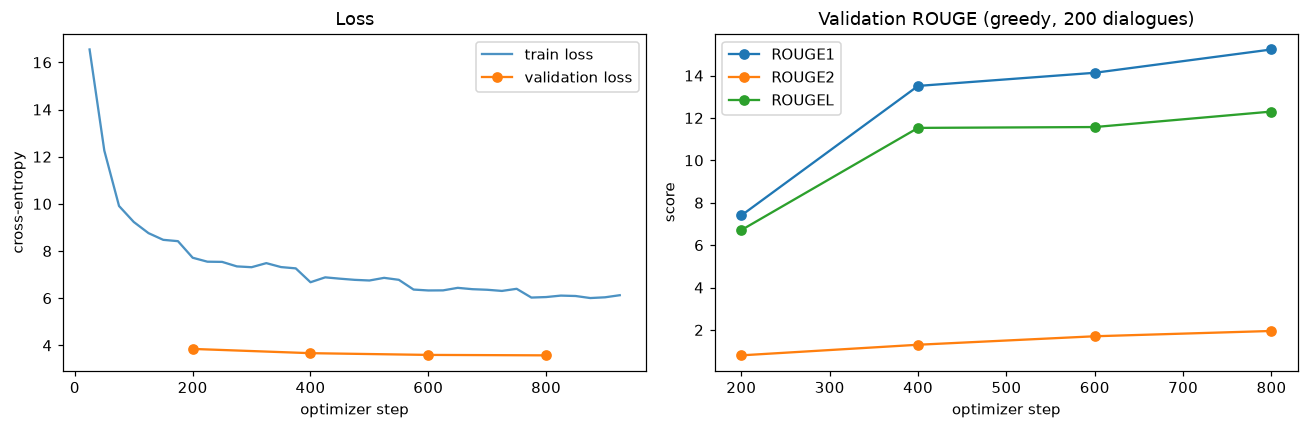

In [18]:
hist = pd.DataFrame(trainer.state.log_history)
train_log = hist[hist["loss"].notna()] if "loss" in hist else pd.DataFrame()
eval_log = hist[hist["eval_loss"].notna()]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
if len(train_log):
    axes[0].plot(train_log["step"], train_log["loss"], label="train loss", alpha=0.8)
axes[0].plot(eval_log["step"], eval_log["eval_loss"], "o-", label="validation loss")
axes[0].set(title="Loss", xlabel="optimizer step", ylabel="cross-entropy")
axes[0].legend()

for m in ["eval_rouge1", "eval_rouge2", "eval_rougeL"]:
    axes[1].plot(eval_log["step"], eval_log[m], "o-", label=m.replace("eval_", "").upper())
axes[1].set(title="Validation ROUGE (greedy, 200 dialogues)", xlabel="optimizer step", ylabel="score")
axes[1].legend()
plt.tight_layout()
plt.show()

## 5. Evaluation on the Test Set (CRISP-DM: Evaluation)

We compare:
* **Lead-3 baseline:** simply returns the first three chat lines. This is a standard extractive baseline for SAMSum.
* **Greedy decoding:** picks the most likely token each step; fast but can be repetitive.
* **Beam search (4 beams):** keeps the 4 best partial summaries, blocks repeated trigrams.
* **Beam search + length penalty 2.0:** nudges beams toward longer, more complete summaries.

To reload the trained model in a fresh session:
```python
model = EncoderDecoderModel.from_pretrained(FINAL_MODEL_DIR).to(device)
```

In [19]:
@torch.no_grad()
def generate_summaries(dialogues, batch_size=16, max_new_tokens=MAX_TARGET_LEN, **gen_kwargs):
    model.eval()
    outputs = []
    for i in range(0, len(dialogues), batch_size):
        enc = enc_tok(dialogues[i:i + batch_size], max_length=MAX_INPUT_LEN, truncation=True,
                      padding=True, return_token_type_ids=False, return_tensors="pt").to(device)
        ids = model.generate(input_ids=enc["input_ids"], attention_mask=enc["attention_mask"],
                             max_new_tokens=max_new_tokens, **gen_kwargs)
        outputs.extend(s.strip() for s in dec_tok.batch_decode(ids, skip_special_tokens=True))
    return outputs

def lead3(dialogue):
    return "\n".join(dialogue.split("\n")[:3])

DECODING = {
    "greedy":      dict(num_beams=1, do_sample=False),
    "beam4":       dict(num_beams=4, no_repeat_ngram_size=3, early_stopping=True),
    "beam4_lp2.0": dict(num_beams=4, no_repeat_ngram_size=3, early_stopping=True, length_penalty=2.0),
}

In [20]:
# list(...) needed: datasets 4.x returns a Column object, not a list
test_dialogues = list(test_raw["dialogue"])
test_refs = list(test_raw["summary"])

preds = {"lead3_baseline": [lead3(d) for d in test_dialogues]}
timings = {"lead3_baseline": 0.0}
for name, kw in DECODING.items():
    t0 = time.time()
    preds[name] = generate_summaries(test_dialogues, **kw)
    timings[name] = time.time() - t0
    print(f"{name:12s} done in {timings[name]:.0f}s")

rows = []
for name, p in preds.items():
    r = compute_rouge(p, test_refs)
    r["avg_words"] = round(float(np.mean([len(x.split()) for x in p])), 1)
    r["ms_per_dialogue"] = round(1000 * timings[name] / len(p), 1)
    rows.append({"method": name, **r})

results_df = pd.DataFrame(rows).set_index("method")
results_df.to_csv("test_results.csv")
print(f"Reference summaries average {np.mean([len(x.split()) for x in test_refs]):.1f} words")
results_df

greedy       done in 746s


KeyboardInterrupt: 

In [24]:
DECODING = {"greedy": DECODING["greedy"], "beam4": DECODING["beam4"]}
t0 = time.time()
preds["beam4"] = generate_summaries(test_dialogues, max_new_tokens=60, **DECODING["beam4"])
timings["beam4"] = time.time() - t0
print(f"beam4 done in {timings['beam4']:.0f}s")

beam4 done in 1351s


In [25]:
rows = []
for name, p in preds.items():
    if len(p) != len(test_refs):
        continue
    r = compute_rouge(p, test_refs)
    r["avg_words"] = round(float(np.mean([len(x.split()) for x in p])), 1)
    r["ms_per_dialogue"] = round(1000 * timings.get(name, 0) / len(p), 1)
    rows.append({"method": name, **r})

results_df = pd.DataFrame(rows).set_index("method")
results_df.to_csv("test_results.csv")
results_df

,rouge1,rouge2,rougeL,rougeLsum,avg_words,ms_per_dialogue
method,,,,,,
lead3_baseline,31.34,8.68,24.21,29.67,23.6,0.0
greedy,15.02,2.02,12.53,13.80,24.4,911.2
beam4,16.70,2.47,13.11,15.49,23.7,1649.9


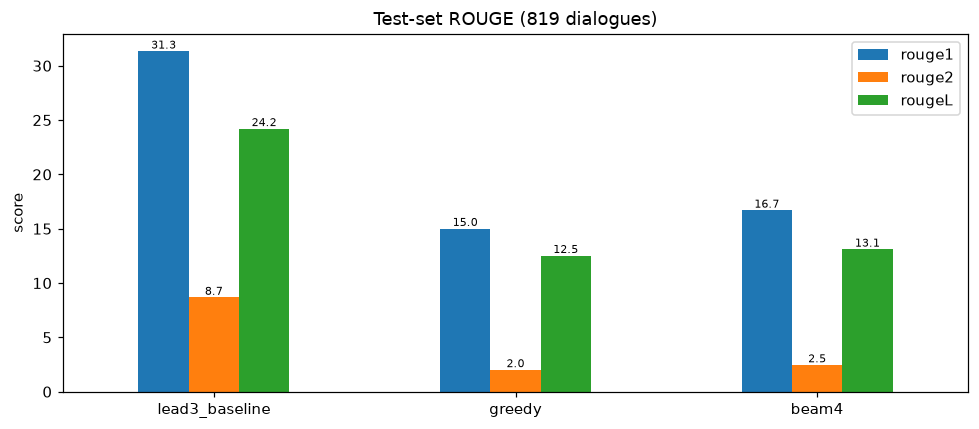

Best decoding strategy: beam4


In [26]:
ax = results_df[["rouge1", "rouge2", "rougeL"]].plot.bar(figsize=(9, 4), rot=0)
ax.set(title=f"Test-set ROUGE ({len(test_refs)} dialogues)", ylabel="score", xlabel="")
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f", fontsize=7)
plt.tight_layout()
plt.show()

BEST = results_df.drop(index="lead3_baseline")["rougeL"].idxmax()
print("Best decoding strategy:", BEST)

## 6. Qualitative and Error Analysis (CRISP-DM: Evaluation)

In [27]:
rng = random.Random(SEED)
for i in rng.sample(range(len(test_dialogues)), 4):
    print("=" * 100)
    print(test_dialogues[i])
    print("-" * 100)
    print("REFERENCE :", test_refs[i])
    print("GREEDY    :", preds["greedy"][i])
    print(f"{BEST.upper():10s}:", preds[BEST][i])

Richie: Pogba
Clay: Pogboom
Richie: what a s strike yoh!
Clay: was off the seat the moment he chopped the ball back to his right foot
Richie: me too dude
Clay: hope his form lasts
Richie: This season he's more mature
Clay: Yeah, Jose has his trust in him
Richie: everyone does
Clay: yeah, he really deserved to score after his first 60 minutes
Richie: reward
Clay: yeah man
Richie: cool then 
Clay: cool
----------------------------------------------------------------------------------------------------
REFERENCE : Richie and Clay saw a very good football game, with one football player chopping the ball back to his foot, which was particularly exciting. Jose has trust in that player.
GREEDY    : Jake and Mike are going to the party tonight. Jake is going to the party with Mike. Jake is going to the party with Mike.
BEAM4     : Jake is looking for a new job. He's looking for someone who can help him find a good job. Jake is not sure if he should go for a job interview.
Lincoln: Heeyyy ;* wh

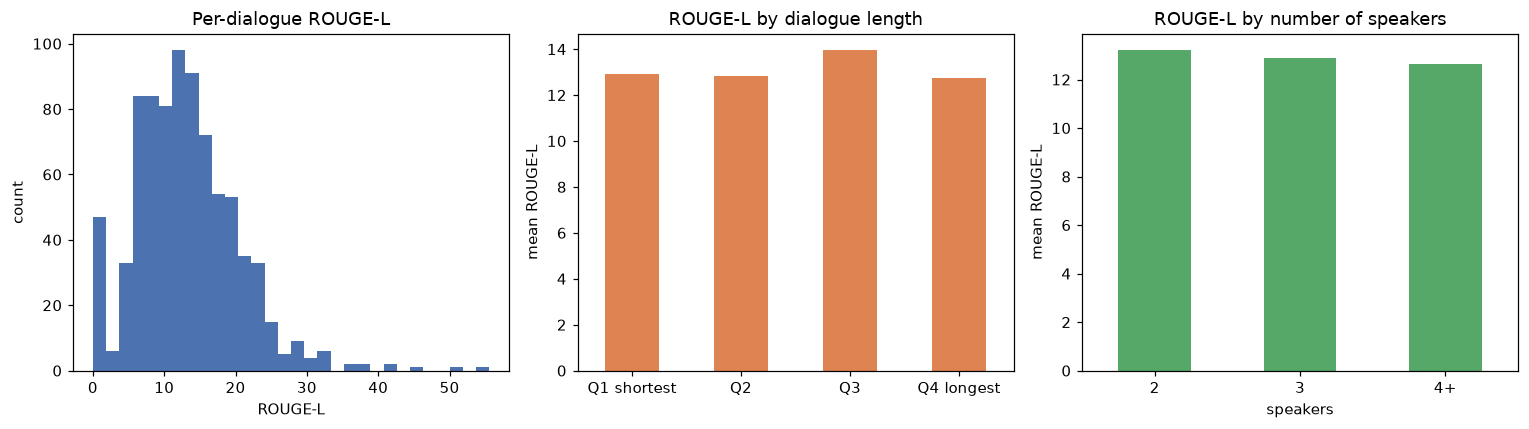

Correlation, dialogue length vs ROUGE-L: 0.012
Correlation, pred length vs ref length: 0.48


In [28]:
per = compute_rouge(preds[BEST], test_refs, aggregate=False)
an = pd.DataFrame({
    "dialogue": test_dialogues,
    "reference": test_refs,
    "prediction": preds[BEST],
    "rouge1": per["rouge1"],
    "rouge2": per["rouge2"],
    "rougeL": per["rougeL"],
})
an["dlg_words"] = an["dialogue"].str.split().str.len()
an["speakers"] = an["dialogue"].apply(lambda d: len(speakers_of(d)))
an["pred_words"] = an["prediction"].str.split().str.len()
an["ref_words"] = an["reference"].str.split().str.len()
an["length_bucket"] = pd.qcut(an["dlg_words"], 4, labels=["Q1 shortest", "Q2", "Q3", "Q4 longest"])
an["speaker_group"] = an["speakers"].clip(upper=4).map(lambda s: f"{s}" if s < 4 else "4+")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].hist(an["rougeL"], bins=30, color="#4C72B0")
axes[0].set(title="Per-dialogue ROUGE-L", xlabel="ROUGE-L", ylabel="count")

an.groupby("length_bucket", observed=True)["rougeL"].mean().plot.bar(ax=axes[1], rot=0, color="#DD8452")
axes[1].set(title="ROUGE-L by dialogue length", xlabel="", ylabel="mean ROUGE-L")

an.groupby("speaker_group")["rougeL"].mean().plot.bar(ax=axes[2], rot=0, color="#55A868")
axes[2].set(title="ROUGE-L by number of speakers", xlabel="speakers", ylabel="mean ROUGE-L")
plt.tight_layout()
plt.show()

print("Correlation, dialogue length vs ROUGE-L:", round(an["dlg_words"].corr(an["rougeL"]), 3))
print("Correlation, pred length vs ref length:", round(an["pred_words"].corr(an["ref_words"]), 3))

In [29]:
def show(rows, title):
    print("#" * 100 + f"\n{title}\n" + "#" * 100)
    for _, r in rows.iterrows():
        print(f"\n[ROUGE-L {r.rougeL:.1f} | {r.dlg_words} words | {r.speakers} speakers]")
        print(r.dialogue[:600] + ("..." if len(r.dialogue) > 600 else ""))
        print("  REF :", r.reference)
        print("  PRED:", r.prediction)

show(an.nlargest(3, "rougeL"), "BEST CASES")
show(an.nsmallest(3, "rougeL"), "WORST CASES")

####################################################################################################
BEST CASES
####################################################################################################

[ROUGE-L 55.6 | 19 words | 2 speakers]
Ann: Are you coming home for lunch?
Pete: Yes be right there
Ann: Okay
Pete: 20 min or so
  REF : Pete will be home for lunch in about 20 minutes.
  PRED: Anna will be home in about an hour.

[ROUGE-L 50.0 | 23 words | 2 speakers]
Patricia: Hey, could you give me a call in an hour or so, I can't talk now.
George: Yeah, of course.
Patricia: Thanks.
  REF : Patricia cannot talk now. George will call her in about an hour.
  PRED: Anna will be home in about an hour.

[ROUGE-L 44.4 | 31 words | 2 speakers]
Fiona: hey
Anna: hello 
Fiona: can you go with me to a doc? 
Fiona: I need support 
Anna: yeah sure 
Fiona: thank you so much 
Fiona: it's tomorrow at 8 a.m.
  REF : Anna will go with Fiona to a doctor tomorrow at 8 a.m.
  PRED: Anna is goi

### Factual-consistency checks (heuristic)
ROUGE rewards word overlap but not correctness. Two simple checks target the most damaging errors for a chat product:
* **Unsupported names:** capitalized names in the summary that never appear in the dialogue, a likely hallucination.
* **Speaker recall:** of the participants the reference summary mentions, how many the model also mentions. This shows whether it tracks *who* did what.

These are heuristics, so flagged examples should be reviewed by hand.

In [30]:
COMMON_CAPS = {"The", "They", "She", "He", "His", "Her", "There", "Both", "Everyone", "Nobody",
               "Today", "Tomorrow", "Tonight", "Yesterday", "Monday", "Tuesday", "Wednesday",
               "Thursday", "Friday", "Saturday", "Sunday", "Christmas", "Easter"}

def unsupported_names(pred, dialogue):
    words = set(re.findall(r"\b[A-Z][a-z]{2,}\b", pred))
    dl = dialogue.lower()
    return sorted(w for w in words if w not in COMMON_CAPS and w.lower() not in dl)

def speaker_recall(pred, ref, dialogue):
    in_ref = [s for s in speakers_of(dialogue) if s.lower() in ref.lower()]
    if not in_ref:
        return np.nan
    return float(np.mean([s.lower() in pred.lower() for s in in_ref]))

an["unsupported"] = [unsupported_names(p, d) for p, d in zip(an["prediction"], an["dialogue"])]
an["speaker_recall"] = [speaker_recall(p, r, d) for p, r, d in zip(an["prediction"], an["reference"], an["dialogue"])]

flagged = an[an["unsupported"].str.len() > 0]
print(f"Summaries with possibly hallucinated names: {len(flagged)}/{len(an)} ({100 * len(flagged) / len(an):.1f}%)")
print(f"Mean speaker recall: {an['speaker_recall'].mean() * 100:.1f}%")
flagged[["prediction", "unsupported", "reference"]].head(5)

Summaries with possibly hallucinated names: 782/819 (95.5%)
Mean speaker recall: 1.2%


,prediction,unsupported,reference
0,Jane is going to the gym today. She's not sure if she'll be able to join her friends.,[Jane],Hannah needs Betty's number but Amanda doesn't have it. She needs to contact Larry.
1,Anna is going to the cinema tonight. She's going to watch a horror movie. She likes horror movies.,[Anna],Eric and Rob are going to watch a stand-up on youtube.
2,Jane is going to buy a new dress for her birthday. She will wear it in the evening.,[Jane],Lenny can't decide which trousers to buy. Bob advised Lenny on that topic. Lenny goes with Bob's advice to pick the trousers that are of best quality.
3,Anna will be home in about an hour. She will bring some food.,[Anna],Emma will be home soon and she will let Will know.
4,"Anna is going to the cinema tonight. She's going to buy some wine and some snacks. Anna will bring some food. Anna wants to go for a walk, but she's not sure if she'll be able to make it in time. ...",[Anna],Jane is in Warsaw. Ollie and Jane has a party. Jane lost her calendar. They will get a lunch this week on Friday. Ollie accidentally called Jane and talked about whisky. Jane cancels lunch. They'l...


**Error patterns (from the outputs above)**

The model has learned the *form* of a SAMSum summary but not the *content* of the conversation in front of it.

* **It ignores the conversation.** Predictions are generic templates built around a handful of stock names ("Jane is going to the gym…", "Anna will be home in about an hour"). On the football chat between Richie and Clay, beam search wrote "Jake is looking for a new job."
* **Hallucinated names are almost universal.** **95.5%** of summaries (782 of 819) contain a name that never appears in the dialogue, and **speaker recall is 1.2%**: the model almost never names the people actually talking.
* **Scores are flat across chat types.** Mean ROUGE-L stays around 13 for every dialogue-length quartile and for 2, 3 and 4+ speakers, and the correlation between dialogue length and ROUGE-L is 0.01. A model that read its input would do worse on long, multi-party chats; flat scores are another sign that it isn't reading them.
* **Its "best" cases are luck.** The top-scoring prediction ("Anna will be home in about an hour") was produced for two different chats and scores well only because common words like "home" and "hour" overlap with the reference.
* **Likely cause.** GPT-2 has no padding token, so `<|endoftext|>` serves as the pad, start and end token. Because padding is excluded from attention, the decoder's start position may be masked during training but not during generation, leaving the decoder unconditioned on the encoder. Undertrained cross-attention (28.4M new weights, only 3,000 dialogues at a learning rate of 5e-5) likely compounds this.

## 7. Inference Demo — Acme Group Chat (CRISP-DM: Deployment)

In [31]:
def summarize(dialogue, **overrides):
    kw = {**DECODING[BEST], **overrides}
    return generate_summaries([clean_text(dialogue)], **kw)[0]

acme_chat = """Priya: Hey team, quick update on Friday's offsite
Marcus: Is it still at the lake house?
Priya: No, we moved it to the downtown office because of the storm forecast
Jenna: Ok. What time do we start?
Priya: 9:30, breakfast is provided
Marcus: I'll bring the projector
Jenna: I can't make it before 11, I have a dentist appointment
Priya: No problem, we'll do the planning session after lunch then"""

print(acme_chat, "\n")
print("SUMMARY:", summarize(acme_chat))

Priya: Hey team, quick update on Friday's offsite
Marcus: Is it still at the lake house?
Priya: No, we moved it to the downtown office because of the storm forecast
Jenna: Ok. What time do we start?
Priya: 9:30, breakfast is provided
Marcus: I'll bring the projector
Jenna: I can't make it before 11, I have a dentist appointment
Priya: No problem, we'll do the planning session after lunch then 

SUMMARY: Kate and Kate are going to the gym tomorrow. Kate will be there in 5 minutes. Kate and Kate will meet at the gym at 7.30.


## 8. Findings, Limitations and Next Steps (CRISP-DM: Deployment)

**Results summary (test set, 819 dialogues)**

| Method | ROUGE-1 | ROUGE-2 | ROUGE-L | Avg words |
|---|---|---|---|---|
| Lead-3 baseline | 31.34 | 8.68 | 24.21 | 23.6 |
| BERT→GPT-2, greedy | 15.02 | 2.02 | 12.53 | 24.4 |
| BERT→GPT-2, beam 4 | 16.70 | 2.47 | 13.11 | 23.7 |

*Training: 3,000 dialogues, 5 epochs (940 optimizer steps), best checkpoint at step 800, best validation ROUGE-L 12.3, 223 minutes on a GTX 1650 SUPER.*

**Key findings**
1. **The pipeline works end to end.** Data cleaning, tokenization with two different vocabularies, warm-started encoder-decoder training with checkpointing and early stopping, ROUGE evaluation, decoding comparison and error analysis all run successfully on a 4 GB consumer GPU.
2. **The model learned the format, not the content.** Before training it produced unrelated news-style text; after training it produces short, fluent, third-person summaries of the right length (about 24 words versus 20 in the references). However, the summaries are generic and almost never mention the actual participants (speaker recall 1.2%).
3. **It does not yet beat the simple baseline.** Copying the first three lines scores about twice as high on every ROUGE metric. A summary that reuses the chat's own names and words overlaps with the reference far more than a fluent but unrelated sentence.
4. **Beam search helps a little.** Beam 4 improves on greedy by about 1.7 ROUGE-1 and 0.6 ROUGE-L, at roughly 1.8× the generation time. Better decoding cannot compensate for a model that isn't using the input.
5. **The Acme demo shows the same problem.** For the offsite chat between Priya, Marcus and Jenna, the model wrote "Kate and Kate are going to the gym tomorrow," with no participant, place or time from the conversation.

**Design choices and rationale**
* *BERT encoder + GPT-2 decoder:* matches the brief and uses two free, well-understood checkpoints; BERT reads the whole conversation bidirectionally while GPT-2 is already a fluent generator.
* *Dynamic padding, fp16, gradient accumulation:* make training feasible on a free GPU.
* *ROUGE-L for model selection:* the standard SAMSum metric, which tracks fluency and content order better than ROUGE-1 alone.

**Limitations**
* BERT's 512-token limit truncates very long group chats.
* Cross-attention is learned from scratch, so a small training set limits quality; purpose-built seq2seq models (BART, PEGASUS) pre-train these layers.
* ROUGE does not measure factual correctness; a wrong name can still score well.
* SAMSum chats are written in English by linguists, so real Acme chats (slang, emojis, many languages) will be harder.

**Next steps**
1. Fix the special tokens first: add a dedicated `[PAD]` token to the GPT-2 tokenizer so the decoder start position is never masked, then confirm the model's output changes with its input before a long run.
2. Raise the learning rate to `1e-4`, train on the full dataset (`USE_SUBSET=False`) on a Colab T4, and compare with BERT2BERT (`DECODER_NAME="bert-base-uncased"`).
3. Benchmark against `facebook/bart-base` as an upper reference point.
4. Tune beam size, length penalty and learning rate.
5. Add a factual-consistency filter before showing summaries to users.
6. For production: chunk long chats, summarize only unread messages, and run a small human evaluation with Acme users.

**Business implications.** Even a moderate-quality summary ("Priya moved the offsite downtown; it starts at 9:30") lets users catch up in seconds instead of scrolling. That supports Acme's goals of reducing information overload and improving engagement, provided summaries are labeled as AI-generated and errors in names and times are kept low.